In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [63]:
df = pd.read_csv("cloud_infrastructure_cost_100000_records_noisy.csv")

In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102000 entries, 0 to 101999
Data columns (total 24 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Server_ID               102000 non-null  object 
 1   Cloud_Provider          102000 non-null  object 
 2   Region                  100467 non-null  object 
 3   Instance_Type           102000 non-null  object 
 4   Environment             100983 non-null  object 
 5   Application_Type        99966 non-null   object 
 6   CPU_Usage_Percent       98928 non-null   object 
 7   Memory_Usage_Percent    98936 non-null   float64
 8   Storage_GB              98942 non-null   float64
 9   Network_Traffic_GB      98811 non-null   object 
 10  Running_Hours           101695 non-null  float64
 11  VM_Count                102000 non-null  int64  
 12  Database_Queries        99968 non-null   float64
 13  Active_Users            98941 non-null   float64
 14  Peak_CPU_Usage      

In [65]:
df.describe()

,Memory_Usage_Percent,Storage_GB,Running_Hours,VM_Count,Database_Queries,Active_Users,Peak_CPU_Usage,Memory_Hour_Rate,Storage_GB_Rate,Network_GB_Rate,Region_Pricing_Factor,Discount_Percentage
count,98936.000000,98942.000000,101695.000000,102000.000000,9.996800e+04,98941.000000,102000.000000,102000.000000,102000.000000,102000.000000,102000.000000,98937.000000
mean,56.218573,598.291304,587.560677,5.761627,2.776635e+06,1172.124488,66.449209,0.006140,0.078525,0.078284,1.023226,15.375477
std,12.126820,990.077753,181.845544,6.830118,1.654028e+07,4177.431166,17.957811,0.005353,0.008022,0.009851,0.071830,11.684287
min,8.420000,-3433.460000,-694.000000,0.000000,8.726000e+03,2.000000,1.500000,0.002270,0.064860,0.059800,0.000000,0.000000
25%,48.110000,217.910000,498.000000,2.000000,4.341402e+05,124.000000,54.100000,0.003170,0.071700,0.070160,0.979100,7.030000
50%,56.370000,383.965000,671.000000,3.000000,9.336555e+05,481.000000,66.920000,0.004560,0.077330,0.079220,1.030400,13.380000
75%,64.340000,703.702500,706.000000,7.000000,2.330908e+06,1310.000000,79.420000,0.007670,0.085980,0.086340,1.081200,20.230000
max,149.990000,62899.260000,1999.000000,37.000000,2.157685e+09,341093.000000,100.000000,0.029590,0.092220,0.095700,1.136800,199.700000


In [66]:
df

,Server_ID,Cloud_Provider,Region,Instance_Type,Environment,Application_Type,CPU_Usage_Percent,Memory_Usage_Percent,Storage_GB,Network_Traffic_GB,...,Peak_CPU_Usage,Peak_Memory_Usage,CPU_Hour_Rate,Memory_Hour_Rate,Storage_GB_Rate,Network_GB_Rate,Region_Pricing_Factor,Discount_Percentage,Reserved_Instance_Flag,Monthly_Cost_USD
0,SRV-025115,AWS,us-east-1,medium,Production,Web,46.98,68.48,228.21,880.16,...,47.65,75.5,0.02626,0.00331,0.08265,0.09054,1.0103,13.40,0,150.97
1,SRV-017472,AWS,us-west-2,xlarge,Production,Analytics,80.04,52.97,742.55,NaN,...,94.58,61.4,0.05641,0.00848,0.08563,0.09250,1.0470,26.34,1,661.61
2,SRV-020869,AWS,us-west-2,medium,Production,Web,66.3,58.98,195.11,4989.61,...,70.75,72.13,0.02705,0.00329,0.09068,0.08297,1.0332,32.10,1,336.11
3,SRV-055813,AWS,eu-west-1,small,Production,Database,76.76,62.03,1004.60,1158.76,...,82.47,66.59,0.02376,0.00245,0.09069,0.09474,1.1178,7.47,0,267.24
4,SRV-009326,Azure,eastus,medium,Development,Analytics,64.38,57.69,253.07,516.48,...,75.47,65.81,0.02633,0.00356,0.07506,0.08133,0.9936,18.77,1,86.28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101995,SRV-005427,GCP,us-east1,medium,Production,Web,40.34,42.35,183.30,1131.67,...,45.77,45.53,0.02372,0.00299,0.07185,0.06383,1.0130,12.41,0,119.57
101996,SRV-043442,Azure,westeurope,medium,Development,Web,33.77,28.30,550.71,1059.08,...,53.23,30.33,0.02588,0.00312,0.07061,0.07597,1.1161,3.89,0,144.61
101997,SRV-047755,AWS,us-west-2,small,Production,API,61.81,73.62,157.60,5454.97,...,62.78,78.13,0.02354,0.00273,0.08381,0.08352,1.0281,4.31,0,482.84
101998,SRV-037961,AWS,ap-southeast-1,medium,Testing,Web,52.75,55.23,165.09,2520.06,...,58.75,67.9,0.02644,0.00329,0.08849,0.09464,1.0797,22.84,1,252.84


In [67]:
def generate_cloud_dataset(n_records=102000):
    providers = ["AWS", "Azure", "GCP"]
    regions_map = {
        "AWS": ["us-east-1", "us-west-2", "eu-west-1", "ap-south-1"],
        "Azure": ["eastus", "westus2", "northeurope", "centralindia"],
        "GCP": ["us-central1", "us-east1", "europe-west1", "asia-south1"]
    }
    region_multiplier_map = {
        "us-east-1": 1.00, "us-west-2": 1.05, "eu-west-1": 1.12, "ap-south-1": 0.95,
        "eastus": 1.00, "westus2": 1.06, "northeurope": 1.14, "centralindia": 0.94,
        "us-central1": 1.00, "us-east1": 1.03, "europe-west1": 1.13, "asia-south1": 0.96
    }
    
    instance_types = ["t3.medium", "m5.large", "m5.xlarge", "c5.2xlarge", "r5.2xlarge"]
    instance_cpu_rate = {"t3.medium": 0.04, "m5.large": 0.09, "m5.xlarge": 0.18, "c5.2xlarge": 0.34, "r5.2xlarge": 0.42}
    instance_mem_rate = {"t3.medium": 0.015, "m5.large": 0.03, "m5.xlarge": 0.06, "c5.2xlarge": 0.09, "r5.2xlarge": 0.16}
    
    environments = ["Development", "Testing", "Production"]
    app_types = ["Web", "API", "Database", "Analytics"]

In [68]:
    # A. Infrastructure Identification Features
providers = ["AWS", "Azure", "GCP"]

regions_map = {
    "AWS": ["us-east-1", "us-west-2", "eu-west-1", "ap-south-1"],
    "Azure": ["eastus", "westus2", "northeurope", "centralindia"],
    "GCP": ["us-central1", "us-east1", "europe-west1", "asia-south1"]
}

instance_types = [
    "t3.medium", "m5.large", "m5.xlarge",
    "c5.2xlarge", "r5.2xlarge"
]

environments = ["Development", "Testing", "Production"]

app_types = ["Web", "API", "Database", "Analytics"]

n_records = 102000
server_ids = [f"SRV-{i:05d}" for i in range(1, n_records + 1)]
cloud_provider = np.random.choice(providers, size=n_records, p=[0.45, 0.30, 0.25])
region = [np.random.choice(regions_map[p]) for p in cloud_provider]
instance_type = np.random.choice(instance_types, size=n_records, p=[0.25, 0.30, 0.22, 0.13, 0.10])
environment = np.random.choice(environments, size=n_records, p=[0.25, 0.20, 0.55])
application_type = np.random.choice(app_types, size=n_records, p=[0.30, 0.30, 0.22, 0.18])

In [69]:
# B. Resource Utilization Features
    # Production servers run more hours and have more VMs/traffic
env_hours_base = np.where(environment == "Production", 700, np.where(environment == "Testing", 420, 300))
running_hours = np.clip(np.random.normal(env_hours_base, 80).astype(int), 50, 744)

vm_count = np.where(environment == "Production", np.random.randint(2, 12, n_records), np.random.randint(1, 5, n_records))
    
cpu_usage = np.clip(np.random.beta(2.5, 2.8, n_records) * 100, 3, 98)
memory_usage = np.clip(cpu_usage * 0.65 + np.random.normal(20, 12, n_records), 5, 99)
    
peak_cpu = np.clip(cpu_usage + np.random.uniform(5, 28, n_records), cpu_usage, 100)
peak_memory = np.clip(memory_usage + np.random.uniform(4, 22, n_records), memory_usage, 100)
    
storage_gb = np.where(
np.isin(application_type, ["Database", "Analytics"]),
np.random.lognormal(mean=6.5, sigma=0.8, size=n_records),
np.random.lognormal(mean=5.2, sigma=0.7, size=n_records)
).round(2)
    
active_users = np.where(
    environment == "Production",
    np.random.negative_binomial(5, 0.002, n_records),
    np.random.randint(5, 150, n_records)
)
network_traffic_gb = np.clip((active_users * np.random.uniform(0.05, 0.25, n_records)) + np.random.exponential(50, n_records), 5, 15000).round(2)
database_queries = np.where(
    application_type == "Database",
    (active_users * np.random.uniform(15, 45, n_records) + 5000).astype(int),
    (active_users * np.random.uniform(3, 15, n_records) + 500).astype(int)
)

In [70]:
  # C. Billing and Pricing Features
region_multiplier_map = {
    "us-east-1": 1.00,
    "us-west-2": 1.05,
    "eu-west-1": 1.12,
    "ap-south-1": 0.95,

    "eastus": 1.00,
    "westus2": 1.06,
    "northeurope": 1.14,
    "centralindia": 0.94,

    "us-central1": 1.00,
    "us-east1": 1.03,
    "europe-west1": 1.13,
    "asia-south1": 0.96
}
cpu_hour_rate = np.array([instance_cpu_rate[it] for it in instance_type]) * np.random.uniform(0.95, 1.05, n_records)
memory_hour_rate = np.array([instance_mem_rate[it] for it in instance_type]) * np.random.uniform(0.95, 1.05, n_records)
storage_gb_rate = np.where(cloud_provider == "AWS", 0.10, np.where(cloud_provider == "Azure", 0.095, 0.09))
network_gb_rate = np.where(cloud_provider == "AWS", 0.09, np.where(cloud_provider == "Azure", 0.087, 0.085))
region_pricing_factor = np.array([region_multiplier_map[r] for r in region])
    
reserved_flag = np.where(environment == "Production", np.random.binomial(1, 0.55, n_records), np.random.binomial(1, 0.15, n_records))
discount_pct = np.where(reserved_flag == 1, np.random.uniform(20, 40, n_records), np.random.uniform(0, 10, n_records)).round(2)

In [71]:
 # D. Target Variable: Monthly_Cost_USD
# Includes base compute + memory + nonlinear burst/autoscaling penalty + storage + tiered network + DB I/O + noise
compute_cost = vm_count * running_hours * (cpu_hour_rate * (0.4 + 0.6 * (cpu_usage / 100.0)) + memory_hour_rate * (0.4 + 0.6 * (memory_usage / 100.0)))
    
# Nonlinear burst penalty when CPU > 75% or Memory > 80% (autoscaling / throttled SLA surcharges)
burst_penalty = 0.025 * (np.maximum(0, cpu_usage - 65) ** 2) + 0.02 * (np.maximum(0, memory_usage - 70) ** 2)
storage_cost = storage_gb * storage_gb_rate

# Network egress tiered discount/cost
network_cost = (network_traffic_gb * network_gb_rate) + 0.000015 * (network_traffic_gb ** 1.5)
db_cost = (database_queries / 100000.0) * 1.25
    
gross_cost = (compute_cost + burst_penalty + storage_cost + network_cost + db_cost) * region_pricing_factor
net_cost = gross_cost * (1 - discount_pct / 100.0)
    
# Realistic market noise / ancillary managed service fees (logs, backups, tax variance ~4%)
noise = np.random.normal(1.03, 0.04, n_records)
monthly_cost_usd = np.clip(net_cost * noise, 10.0, None).round(2)

In [72]:
df = pd.DataFrame({
        "Server_ID": server_ids,
        "Cloud_Provider": cloud_provider,
        "Region": region,
        "Instance_Type": instance_type,
        "Environment": environment,
        "Application_Type": application_type,
        "CPU_Usage_Percent": cpu_usage.round(2),
        "Memory_Usage_Percent": memory_usage.round(2),
        "Storage_GB": storage_gb,
        "Network_Traffic_GB": network_traffic_gb,
        "Running_Hours": running_hours,
        "VM_Count": vm_count,
        "Database_Queries": database_queries,
        "Active_Users": active_users,
        "Peak_CPU_Usage": peak_cpu.round(2),
        "Peak_Memory_Usage": peak_memory.round(2),
        "CPU_Hour_Rate": cpu_hour_rate.round(4),
        "Memory_Hour_Rate": memory_hour_rate.round(4),
        "Storage_GB_Rate": storage_gb_rate,
        "Network_GB_Rate": network_gb_rate,
        "Region_Pricing_Factor": region_pricing_factor,
        "Discount_Percentage": discount_pct,
        "Reserved_Instance_Flag": reserved_flag,
        "Monthly_Cost_USD": monthly_cost_usd
    })


In [73]:
df

,Server_ID,Cloud_Provider,Region,Instance_Type,Environment,Application_Type,CPU_Usage_Percent,Memory_Usage_Percent,Storage_GB,Network_Traffic_GB,...,Peak_CPU_Usage,Peak_Memory_Usage,CPU_Hour_Rate,Memory_Hour_Rate,Storage_GB_Rate,Network_GB_Rate,Region_Pricing_Factor,Discount_Percentage,Reserved_Instance_Flag,Monthly_Cost_USD
0,SRV-00001,AWS,eu-west-1,m5.xlarge,Production,API,59.48,49.91,144.22,260.95,...,70.96,57.61,0.1776,0.0575,0.100,0.090,1.12,39.08,1,729.64
1,SRV-00002,AWS,us-west-2,t3.medium,Production,Web,47.35,55.33,355.03,408.42,...,56.37,73.91,0.0395,0.0153,0.100,0.090,1.05,35.07,1,255.14
2,SRV-00003,AWS,us-west-2,c5.2xlarge,Production,Web,31.01,61.95,174.82,534.17,...,48.52,83.44,0.3521,0.0891,0.100,0.090,1.05,7.08,0,1270.20
3,SRV-00004,AWS,eu-west-1,m5.xlarge,Production,API,41.88,39.68,121.85,256.29,...,67.51,47.05,0.1768,0.0598,0.100,0.090,1.12,8.51,0,388.27
4,SRV-00005,GCP,asia-south1,m5.large,Development,Database,47.94,53.56,587.99,73.56,...,74.75,65.14,0.0941,0.0296,0.090,0.085,0.96,4.94,0,117.94
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101995,SRV-101996,AWS,eu-west-1,m5.large,Production,Web,64.81,62.65,99.06,280.29,...,75.56,74.38,0.0930,0.0311,0.100,0.090,1.12,2.09,0,546.14
101996,SRV-101997,GCP,asia-south1,t3.medium,Testing,Web,63.59,50.50,122.83,42.86,...,91.12,64.85,0.0391,0.0143,0.090,0.085,0.96,0.61,0,63.08
101997,SRV-101998,GCP,asia-south1,m5.xlarge,Development,API,71.66,92.09,163.87,94.30,...,97.51,99.52,0.1868,0.0615,0.090,0.085,0.96,6.24,0,233.38
101998,SRV-101999,GCP,us-east1,t3.medium,Production,Web,25.14,46.39,250.44,275.04,...,34.97,57.40,0.0416,0.0154,0.090,0.085,1.03,30.88,1,213.30


In [74]:
print("Dataset generated successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset generated successfully!
Dataset shape: (102000, 24)


,Server_ID,Cloud_Provider,Region,Instance_Type,Environment,Application_Type,CPU_Usage_Percent,Memory_Usage_Percent,Storage_GB,Network_Traffic_GB,...,Peak_CPU_Usage,Peak_Memory_Usage,CPU_Hour_Rate,Memory_Hour_Rate,Storage_GB_Rate,Network_GB_Rate,Region_Pricing_Factor,Discount_Percentage,Reserved_Instance_Flag,Monthly_Cost_USD
0,SRV-00001,AWS,eu-west-1,m5.xlarge,Production,API,59.48,49.91,144.22,260.95,...,70.96,57.61,0.1776,0.0575,0.10,0.090,1.12,39.08,1,729.64
1,SRV-00002,AWS,us-west-2,t3.medium,Production,Web,47.35,55.33,355.03,408.42,...,56.37,73.91,0.0395,0.0153,0.10,0.090,1.05,35.07,1,255.14
2,SRV-00003,AWS,us-west-2,c5.2xlarge,Production,Web,31.01,61.95,174.82,534.17,...,48.52,83.44,0.3521,0.0891,0.10,0.090,1.05,7.08,0,1270.20
3,SRV-00004,AWS,eu-west-1,m5.xlarge,Production,API,41.88,39.68,121.85,256.29,...,67.51,47.05,0.1768,0.0598,0.10,0.090,1.12,8.51,0,388.27
4,SRV-00005,GCP,asia-south1,m5.large,Development,Database,47.94,53.56,587.99,73.56,...,74.75,65.14,0.0941,0.0296,0.09,0.085,0.96,4.94,0,117.94


In [75]:
print("=== Dataset Info ===")
print(df.info())

print("\n=== Missing Values ===")
print(df.isnull().sum().sum(), "missing values found.")

print("\n=== Numerical Summary ===")
display(df.describe().T[["mean", "std", "min", "50%", "max"]])

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102000 entries, 0 to 101999
Data columns (total 24 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Server_ID               102000 non-null  object 
 1   Cloud_Provider          102000 non-null  object 
 2   Region                  102000 non-null  object 
 3   Instance_Type           102000 non-null  object 
 4   Environment             102000 non-null  object 
 5   Application_Type        102000 non-null  object 
 6   CPU_Usage_Percent       102000 non-null  float64
 7   Memory_Usage_Percent    102000 non-null  float64
 8   Storage_GB              102000 non-null  float64
 9   Network_Traffic_GB      102000 non-null  float64
 10  Running_Hours           102000 non-null  int64  
 11  VM_Count                102000 non-null  int32  
 12  Database_Queries        102000 non-null  int64  
 13  Active_Users            102000 non-null  int32  
 14 

,mean,std,min,50%,max
CPU_Usage_Percent,47.176815,19.896062,3.0000,46.870,98.000
Memory_Usage_Percent,50.691945,17.534505,5.0000,50.530,99.000
Storage_GB,503.649526,646.152051,8.4700,283.350,15299.530
Network_Traffic_GB,261.412306,252.666731,5.0000,183.390,2264.360
Running_Hours,536.092529,183.753174,50.0000,597.000,744.000
VM_Count,4.707843,3.018649,1.0000,4.000,11.000
Database_Queries,20607.475422,29269.117770,515.0000,9554.000,374452.000
Active_Users,1409.413873,1460.014319,5.0000,1186.000,10935.000
Peak_CPU_Usage,63.381684,20.460785,8.0700,63.320,100.000
Peak_Memory_Usage,63.557185,17.981445,9.1000,63.530,100.000


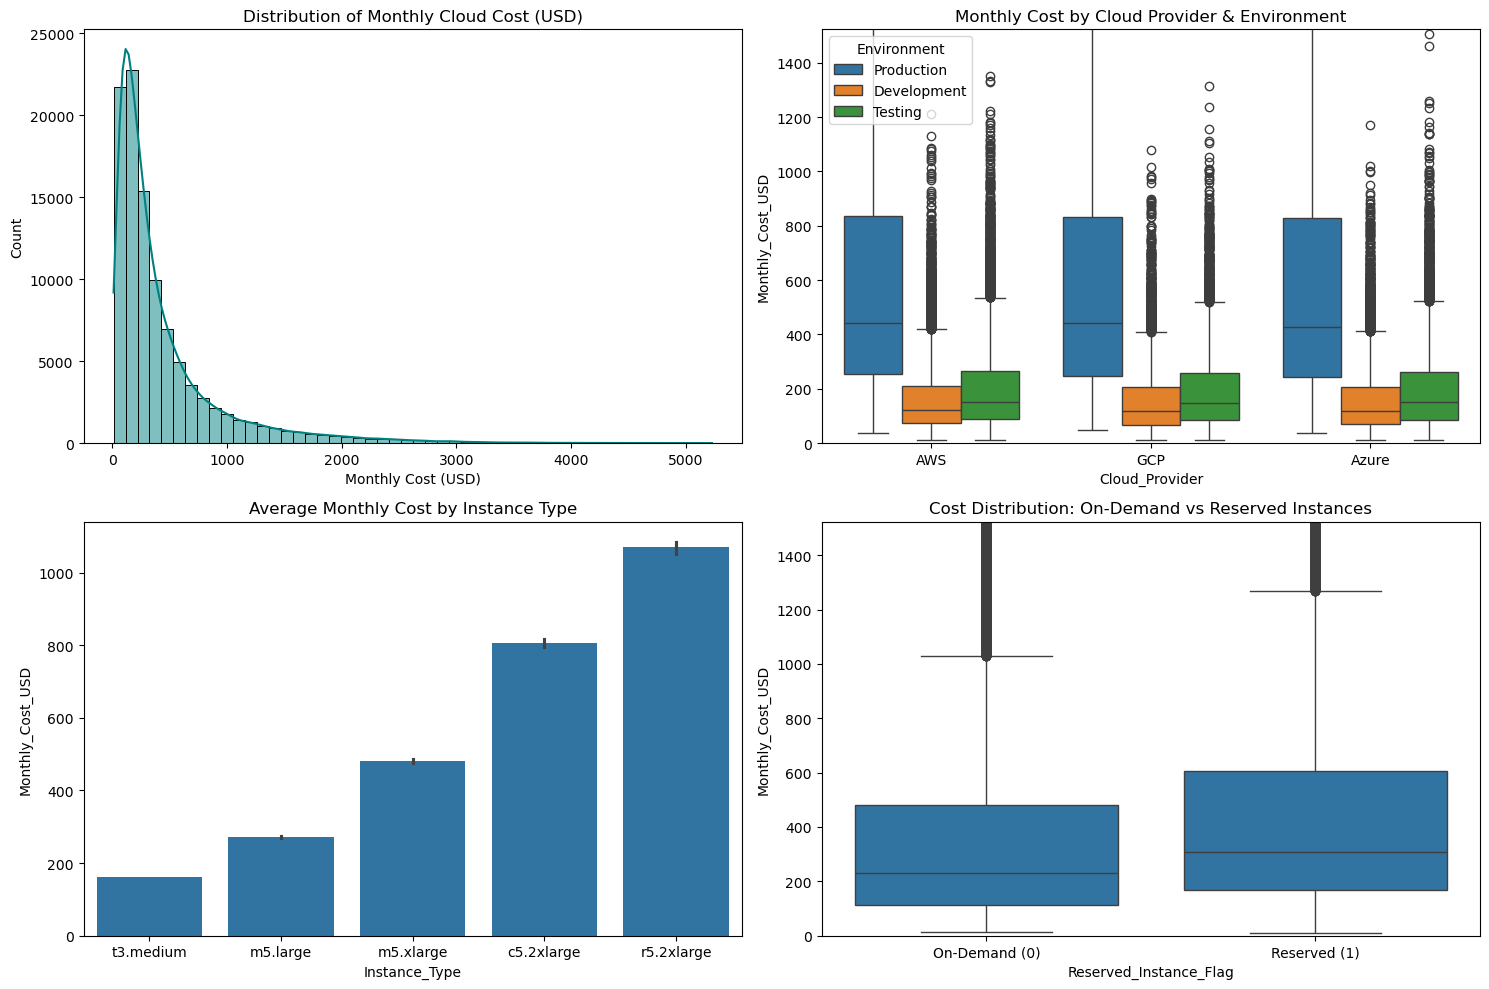

In [76]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Target Distribution
sns.histplot(df["Monthly_Cost_USD"], bins=50, kde=True, ax=axes[0, 0], color="teal")
axes[0, 0].set_title("Distribution of Monthly Cloud Cost (USD)")
axes[0, 0].set_xlabel("Monthly Cost (USD)")

# 2. Cost by Cloud Provider & Environment
sns.boxplot(data=df, x="Cloud_Provider", y="Monthly_Cost_USD", hue="Environment", ax=axes[0, 1])
axes[0, 1].set_title("Monthly Cost by Cloud Provider & Environment")
axes[0, 1].set_ylim(0, df["Monthly_Cost_USD"].quantile(0.95))

# 3. Cost by Instance Type
order_inst = ["t3.medium", "m5.large", "m5.xlarge", "c5.2xlarge", "r5.2xlarge"]
sns.barplot(data=df, x="Instance_Type", y="Monthly_Cost_USD", order=order_inst, ax=axes[1, 0], estimator=np.mean)
axes[1, 0].set_title("Average Monthly Cost by Instance Type")

# 4. Reserved vs On-Demand Cost
sns.boxplot(data=df, x="Reserved_Instance_Flag", y="Monthly_Cost_USD", ax=axes[1, 1])
axes[1, 1].set_xticks([0, 1])
axes[1, 1].set_xticklabels(["On-Demand (0)", "Reserved (1)"])
axes[1, 1].set_title("Cost Distribution: On-Demand vs Reserved Instances")
axes[1, 1].set_ylim(0, df["Monthly_Cost_USD"].quantile(0.95))

plt.tight_layout()
plt.show()

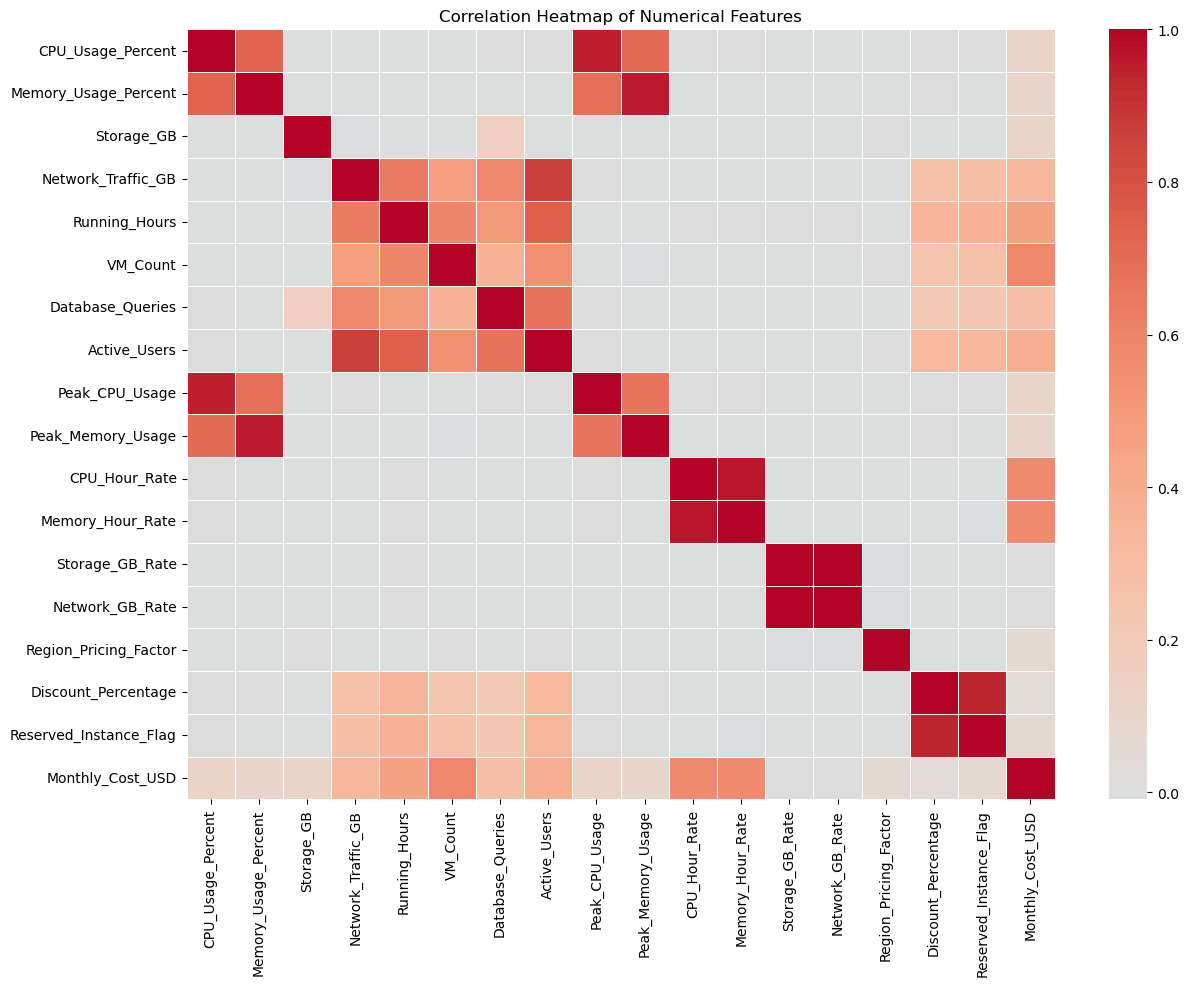

Top 10 Features Correlated with Monthly_Cost_USD:
Monthly_Cost_USD      1.000000
VM_Count              0.578638
CPU_Hour_Rate         0.572332
Memory_Hour_Rate      0.564491
Running_Hours         0.445577
Active_Users          0.385820
Network_Traffic_GB    0.342407
Database_Queries      0.276200
CPU_Usage_Percent     0.120713
Peak_CPU_Usage        0.115707
Storage_GB            0.110383
Name: Monthly_Cost_USD, dtype: float64


In [77]:
# Correlation Heatmap of Numerical Features
num_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[num_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=False, cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

print("Top 10 Features Correlated with Monthly_Cost_USD:")
print(corr_matrix["Monthly_Cost_USD"].sort_values(ascending=False).head(11))

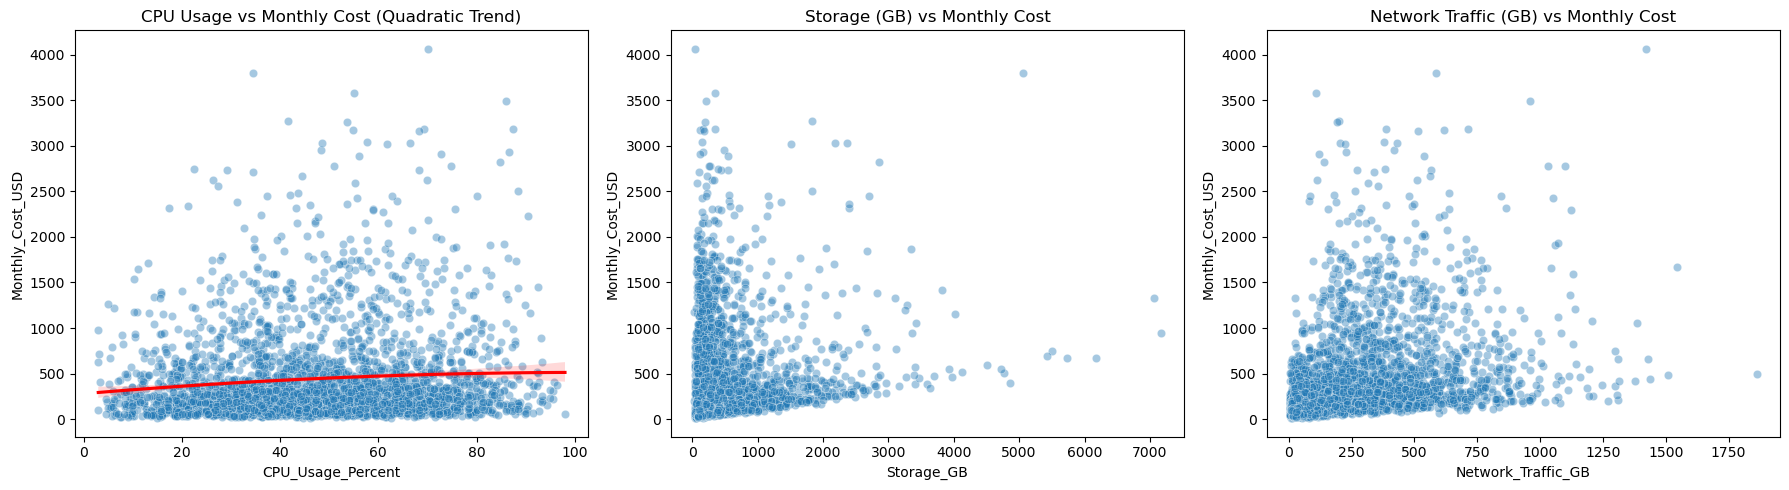

In [78]:
sample_df = df.sample(3000, random_state=42)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=sample_df, x="CPU_Usage_Percent", y="Monthly_Cost_USD", alpha=0.4, ax=axes[0])
sns.regplot(data=sample_df, x="CPU_Usage_Percent", y="Monthly_Cost_USD", scatter=False, order=2, color="red", ax=axes[0])
axes[0].set_title("CPU Usage vs Monthly Cost (Quadratic Trend)")

sns.scatterplot(data=sample_df, x="Storage_GB", y="Monthly_Cost_USD", alpha=0.4, ax=axes[1])
axes[1].set_title("Storage (GB) vs Monthly Cost")

sns.scatterplot(data=sample_df, x="Network_Traffic_GB", y="Monthly_Cost_USD", alpha=0.4, ax=axes[2])
axes[2].set_title("Network Traffic (GB) vs Monthly Cost")

plt.tight_layout()
plt.show()

In [79]:
df_fe = df.copy()

# 1. Total Compute Hours across all VMs
df_fe["Total_VM_Hours"] = df_fe["VM_Count"] * df_fe["Running_Hours"]

# 2. Effective CPU & Memory Load Hours
df_fe["Effective_CPU_Load"] = df_fe["Total_VM_Hours"] * (df_fe["CPU_Usage_Percent"] / 100.0)
df_fe["Effective_Memory_Load"] = df_fe["Total_VM_Hours"] * (df_fe["Memory_Usage_Percent"] / 100.0)

# 3. Peak-to-Average Utilization Gap (measures spikiness / burst risk)
df_fe["CPU_Spike_Gap"] = df_fe["Peak_CPU_Usage"] - df_fe["CPU_Usage_Percent"]

# 4. Flag for Underutilized / Overprovisioned VMs (CPU < 20% and Memory < 25%)
df_fe["Is_Underutilized"] = ((df_fe["CPU_Usage_Percent"] < 20) & (df_fe["Memory_Usage_Percent"] < 25)).astype(int)

# 5. Effective Rate Multiplier (Region factor adjusted by discount)
df_fe["Net_Multiplier"] = df_fe["Region_Pricing_Factor"] * (1 - df_fe["Discount_Percentage"] / 100.0)

# Define Target and Train/Test Split (80/20) - Same split used across ALL experiments!
X = df_fe.drop(columns=["Server_ID", "Monthly_Cost_USD"])
y = df_fe["Monthly_Cost_USD"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(f"Training samples: {X_train.shape[0]}, Testing samples: {X_test.shape[0]}")

Training samples: 81600, Testing samples: 20400


In [80]:
results_list = []

def evaluate_model(name, model, X_tr, X_te, y_tr, y_te):
    model.fit(X_tr, y_tr)
    preds = model.predict(X_te)
    
    mae = mean_absolute_error(y_te, preds)
    rmse = np.sqrt(mean_squared_error(y_te, preds))
    r2 = r2_score(y_te, preds)
    
    results_list.append({
        "Model": name,
        "MAE ($)": round(mae, 2),
        "RMSE ($)": round(rmse, 2),
        "R2 Score": round(r2, 4)
    })
    print(f"[{name}] -> MAE: ${mae:.2f} | RMSE: ${rmse:.2f} | R²: {r2:.4f}")
    return model, preds

In [81]:
results_list = []

def evaluate_model(name, model, X_tr, X_te, y_tr, y_te):
    model.fit(X_tr, y_tr)
    preds = model.predict(X_te)
    
    mae = mean_absolute_error(y_te, preds)
    rmse = np.sqrt(mean_squared_error(y_te, preds))
    r2 = r2_score(y_te, preds)
    
    results_list.append({
        "Model": name,
        "MAE ($)": round(mae, 2),
        "RMSE ($)": round(rmse, 2),
        "R2 Score": round(r2, 4)
    })
    print(f"[{name}] -> MAE: ${mae:.2f} | RMSE: ${rmse:.2f} | R²: {r2:.4f}")
    return model, preds

In [82]:
# Experiment 2A: Core 5 Resource Features
exp2_core_features = [
    "CPU_Usage_Percent", "Memory_Usage_Percent",
    "Storage_GB", "Network_Traffic_GB", "Running_Hours"
]
pipe_exp2_core = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LinearRegression())
])

model_exp2_core, preds_exp2_core = evaluate_model(
    "2. Multiple Linear (5 Core Features)",
    pipe_exp2_core,
    X_train[exp2_core_features], X_test[exp2_core_features],
    y_train, y_test
)

# Experiment 2B: Full Feature Set (Numeric + Engineered + Categoricals)
cat_cols = ["Cloud_Provider", "Region", "Instance_Type", "Environment", "Application_Type"]
num_cols_full = [c for c in X_train.columns if c not in cat_cols]

preprocessor_full = ColumnTransformer([
    ("num", StandardScaler(), num_cols_full),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols)
])

pipe_exp2_full = Pipeline([
    ("prep", preprocessor_full),
    ("lr", LinearRegression())
])

model_exp2_full, preds_exp2_full = evaluate_model(
    "3. Multiple Linear (All Features)",
    pipe_exp2_full,
    X_train, X_test,
    y_train, y_test
)

[2. Multiple Linear (5 Core Features)] -> MAE: $285.16 | RMSE: $444.09 | R²: 0.2297
[3. Multiple Linear (All Features)] -> MAE: $173.74 | RMSE: $256.92 | R²: 0.7422


In [83]:
# Experiment 3A: Polynomial Regression (Degree=2) on Core + Pricing/Scale Features
poly_features = [
    "CPU_Usage_Percent", "Memory_Usage_Percent", "Storage_GB",
    "Network_Traffic_GB", "Running_Hours", "VM_Count",
    "CPU_Hour_Rate", "Memory_Hour_Rate", "Total_VM_Hours",
    "Effective_CPU_Load", "Effective_Memory_Load", "Net_Multiplier"
]

pipe_poly = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("lr", LinearRegression())
])

model_exp3_poly, preds_exp3_poly = evaluate_model(
    "4. Polynomial Regression (Deg 2)",
    pipe_poly,
    X_train[poly_features], X_test[poly_features],
    y_train, y_test
)

# Experiment 3B (Model 5): Polynomial + Categoricals with Ridge Regularization
preprocessor_poly_full = ColumnTransformer([
    ("poly_num", Pipeline([
        ("scaler", StandardScaler()),
        ("poly", PolynomialFeatures(degree=2, include_bias=False))
    ]), num_cols_full),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols)
])

pipe_ridge_poly = Pipeline([
    ("prep", preprocessor_poly_full),
    ("ridge", Ridge(alpha=10.0))
])

model_exp3_ridge, preds_exp3_ridge = evaluate_model(
    "5. Ridge Polynomial (All Features)",
    pipe_ridge_poly,
    X_train, X_test,
    y_train, y_test
)

[4. Polynomial Regression (Deg 2)] -> MAE: $29.01 | RMSE: $47.42 | R²: 0.9912
[5. Ridge Polynomial (All Features)] -> MAE: $28.37 | RMSE: $47.08 | R²: 0.9913


In [84]:
results_df = pd.DataFrame(results_list).sort_values(by="R2 Score", ascending=False)
display(results_df)

,Model,MAE ($),RMSE ($),R2 Score
3,5. Ridge Polynomial (All Features),28.37,47.08,0.9913
2,4. Polynomial Regression (Deg 2),29.01,47.42,0.9912
1,3. Multiple Linear (All Features),173.74,256.92,0.7422
0,2. Multiple Linear (5 Core Features),285.16,444.09,0.2297


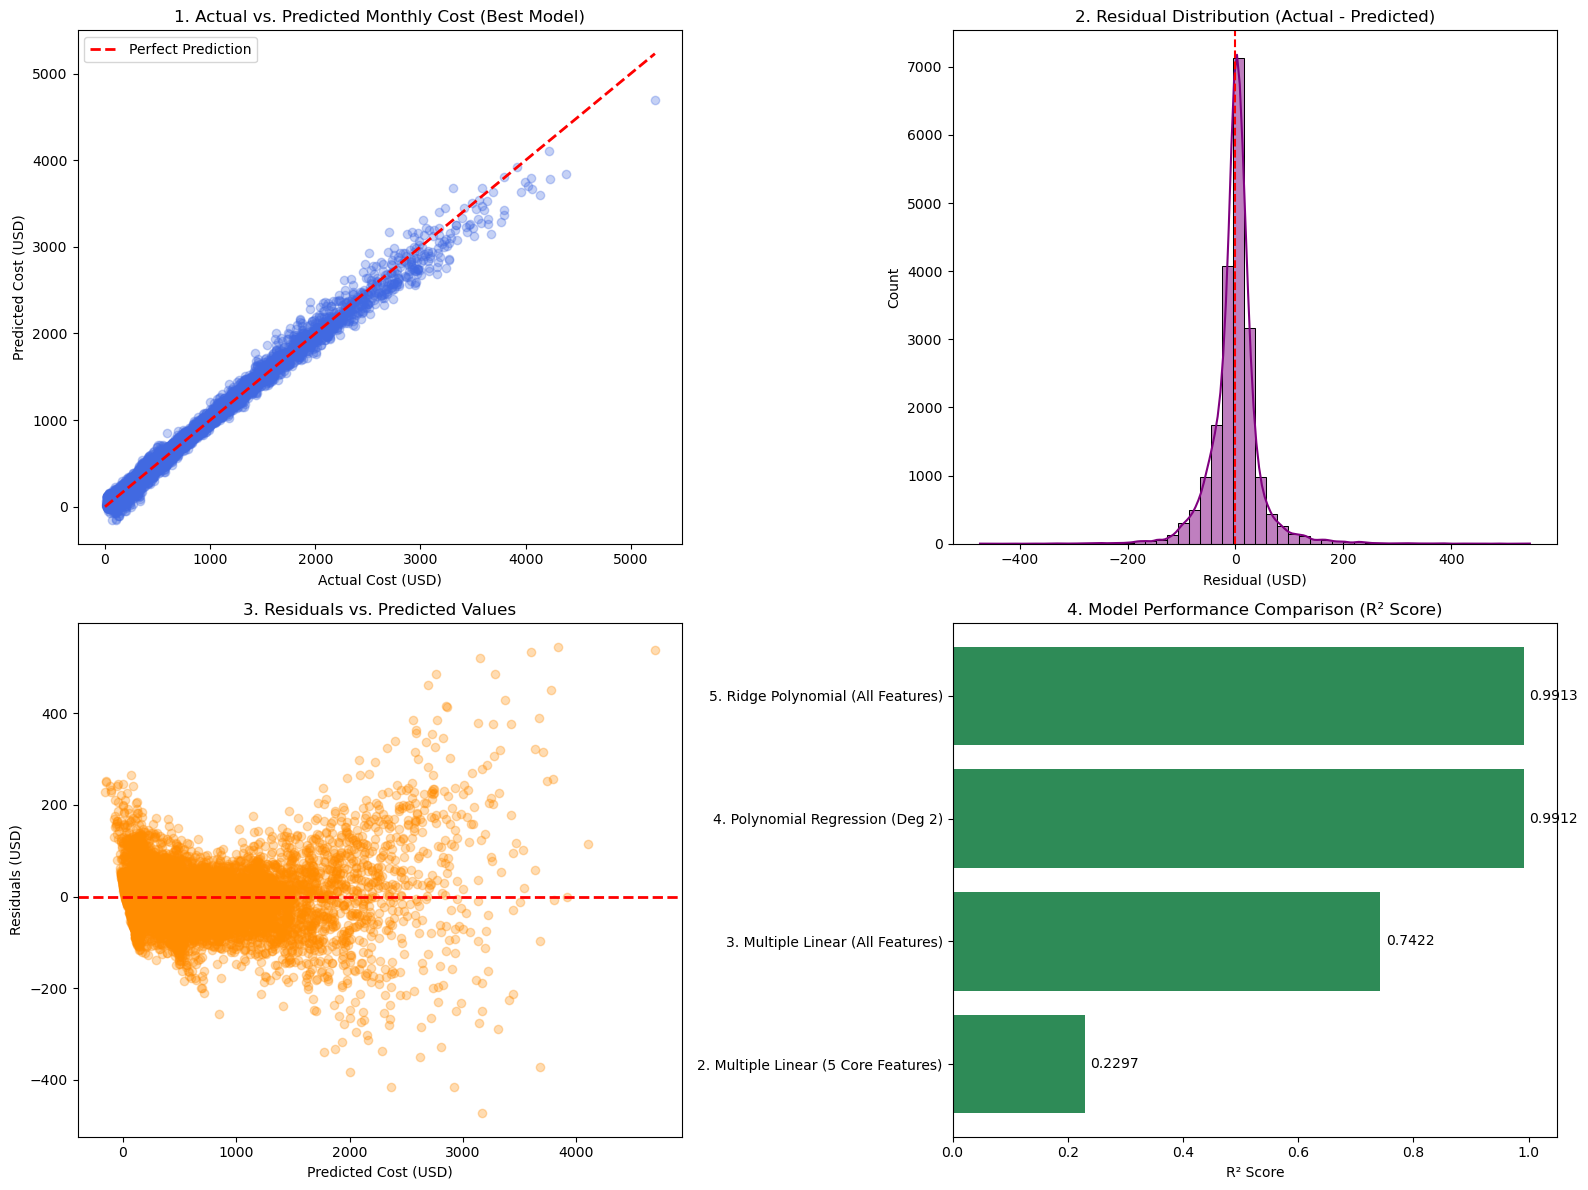

In [85]:
# Use our best-performing model (Model 5: Ridge Polynomial) for residual diagnostics
best_preds = preds_exp3_ridge
residuals = y_test - best_preds

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Actual vs Predicted Cost Graph
axes[0, 0].scatter(y_test, best_preds, alpha=0.3, color="royalblue")
max_val = max(y_test.max(), best_preds.max())
axes[0, 0].plot([0, max_val], [0, max_val], "r--", lw=2, label="Perfect Prediction")
axes[0, 0].set_title("1. Actual vs. Predicted Monthly Cost (Best Model)")
axes[0, 0].set_xlabel("Actual Cost (USD)")
axes[0, 0].set_ylabel("Predicted Cost (USD)")
axes[0, 0].legend()

# 2. Residual Distribution
sns.histplot(residuals, bins=50, kde=True, ax=axes[0, 1], color="purple")
axes[0, 1].axvline(0, color="red", linestyle="--")
axes[0, 1].set_title("2. Residual Distribution (Actual - Predicted)")
axes[0, 1].set_xlabel("Residual (USD)")

# 3. Residual vs Predicted Plot
axes[1, 0].scatter(best_preds, residuals, alpha=0.3, color="darkorange")
axes[1, 0].axhline(0, color="red", linestyle="--", lw=2)
axes[1, 0].set_title("3. Residuals vs. Predicted Values")
axes[1, 0].set_xlabel("Predicted Cost (USD)")
axes[1, 0].set_ylabel("Residuals (USD)")

# 4. Model Performance Comparison Chart (R2 & RMSE)
res_sorted = results_df.sort_values("R2 Score", ascending=True)
axes[1, 1].barh(res_sorted["Model"], res_sorted["R2 Score"], color="seagreen")
axes[1, 1].set_xlim(0, 1.05)
axes[1, 1].set_title("4. Model Performance Comparison (R² Score)")
axes[1, 1].set_xlabel("R² Score")
for index, value in enumerate(res_sorted["R2 Score"]):
    axes[1, 1].text(value + 0.01, index, f"{value:.4f}", va="center")

plt.tight_layout()
plt.show()

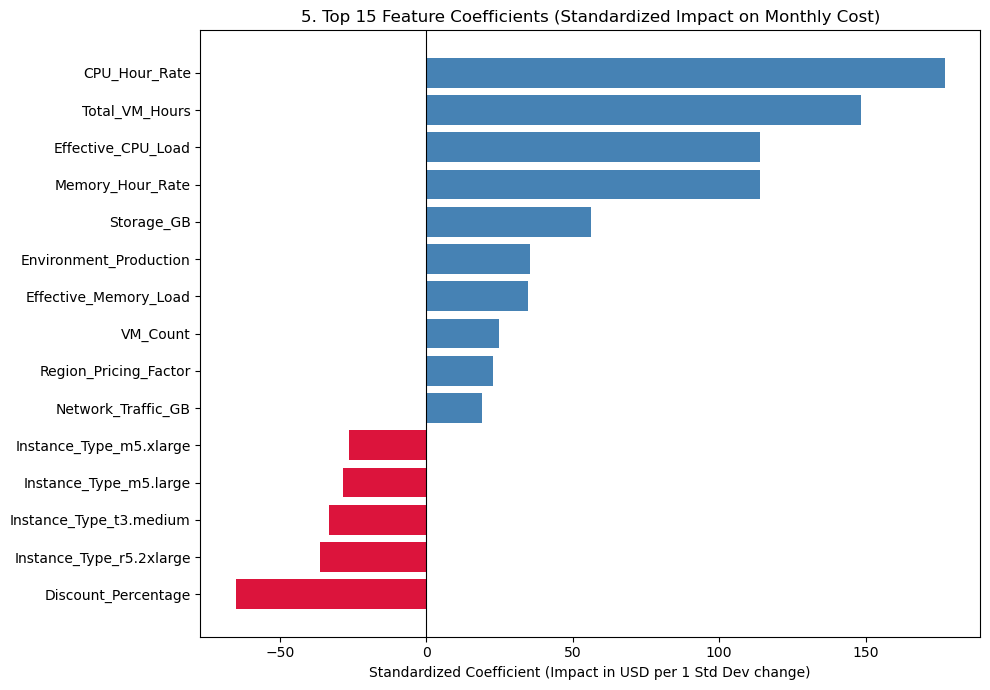

In [86]:
# Extract feature names and coefficients from Model 3
ohe_feature_names = model_exp2_full.named_steps["prep"].named_transformers_["cat"].get_feature_names_out(cat_cols)
all_feature_names = num_cols_full + list(ohe_feature_names)
coefficients = model_exp2_full.named_steps["lr"].coef_

coef_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Coefficient": coefficients,
    "Abs_Coefficient": np.abs(coefficients)
}).sort_values("Abs_Coefficient", ascending=False)

plt.figure(figsize=(10, 7))
top_15 = coef_df.head(15).sort_values("Coefficient")
colors = ["crimson" if x < 0 else "steelblue" for x in top_15["Coefficient"]]
plt.barh(top_15["Feature"], top_15["Coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("5. Top 15 Feature Coefficients (Standardized Impact on Monthly Cost)")
plt.xlabel("Standardized Coefficient (Impact in USD per 1 Std Dev change)")
plt.tight_layout()
plt.show()

In [87]:
baseline_fleet = X_test.copy()
baseline_cost = model_exp3_ridge.predict(baseline_fleet).sum()

scenarios = []
for growth in [0.10, 0.25, 0.50]:
    # Increase CPU, Memory, and Storage
    scen_df = baseline_fleet.copy()
    scen_df["CPU_Usage_Percent"] = np.clip(scen_df["CPU_Usage_Percent"] * (1 + growth), 0, 100)
    scen_df["Memory_Usage_Percent"] = np.clip(scen_df["Memory_Usage_Percent"] * (1 + growth), 0, 100)
    scen_df["Storage_GB"] = scen_df["Storage_GB"] * (1 + growth)
    # Recompute engineered features
    scen_df["Effective_CPU_Load"] = scen_df["Total_VM_Hours"] * (scen_df["CPU_Usage_Percent"] / 100.0)
    scen_df["Effective_Memory_Load"] = scen_df["Total_VM_Hours"] * (scen_df["Memory_Usage_Percent"] / 100.0)
    
    new_cost = model_exp3_ridge.predict(scen_df).sum()
    diff = new_cost - baseline_cost
    scenarios.append({
        "Scenario": f"+{int(growth*100)}% Resource Growth",
        "Predicted Fleet Cost ($)": round(new_cost, 2),
        "Cost Increase ($)": round(diff, 2),
        "% Increase": round((diff / baseline_cost) * 100, 2)
    })

print(f"Baseline Monthly Fleet Cost (Test Fleet of {len(baseline_fleet)} servers): ${baseline_cost:,.2f}")
display(pd.DataFrame(scenarios))

Baseline Monthly Fleet Cost (Test Fleet of 20400 servers): $8,848,482.88


,Scenario,Predicted Fleet Cost ($),Cost Increase ($),% Increase
0,+10% Resource Growth,9234196.86,385713.98,4.36
1,+25% Resource Growth,9806897.98,958415.11,10.83
2,+50% Resource Growth,10672318.53,1823835.65,20.61


In [88]:
opt_df = df_fe.loc[X_test.index].copy()
opt_df["Predicted_Current_Cost"] = model_exp3_ridge.predict(X_test)

# Identify Optimization Candidates
underutilized_mask = (opt_df["CPU_Usage_Percent"] < 20) & (opt_df["Memory_Usage_Percent"] < 25) & (opt_df["VM_Count"] > 1)
ondemand_prod_mask = (opt_df["Environment"] == "Production") & (opt_df["Reserved_Instance_Flag"] == 0)

print(f"Underutilized multi-VM servers identified: {underutilized_mask.sum()}")
print(f"On-Demand Production servers eligible for Reserved Pricing: {ondemand_prod_mask.sum()}")

# Apply Optimization Simulation on X_test copy

X_opt = X_test.copy()

# Action A: Right-size underutilized multi-VM servers (reduce VM_Count by 30%, min 1)
X_opt.loc[underutilized_mask, "VM_Count"] = np.maximum(1, (X_opt.loc[underutilized_mask, "VM_Count"] * 0.7).astype(int))
X_opt["Total_VM_Hours"] = X_opt["VM_Count"] * X_opt["Running_Hours"]
X_opt["Effective_CPU_Load"] = X_opt["Total_VM_Hours"] * (X_opt["CPU_Usage_Percent"] / 100.0)
X_opt["Effective_Memory_Load"] = X_opt["Total_VM_Hours"] * (X_opt["Memory_Usage_Percent"] / 100.0)

# Action B: Reserve Production Instances (set Reserved_Instance_Flag = 1, Discount = 30%)
X_opt.loc[ondemand_prod_mask, "Reserved_Instance_Flag"] = 1
X_opt.loc[ondemand_prod_mask, "Discount_Percentage"] = 30.0
X_opt["Net_Multiplier"] = X_opt["Region_Pricing_Factor"] * (1 - X_opt["Discount_Percentage"] / 100.0)

optimized_cost = model_exp3_ridge.predict(X_opt).sum()
savings = baseline_cost - optimized_cost

print(f"\n--- Optimization Summary (Test Fleet) ---")
print(f"Current Monthly Cost:   ${baseline_cost:,.2f}")
print(f"Optimized Monthly Cost: ${optimized_cost:,.2f}")
print(f"Estimated Monthly Savings: ${savings:,.2f} ({(savings/baseline_cost)*100:.2f}% reduction)")
print(f"Projected Annual Savings:  ${savings*12:,.2f}")

Underutilized multi-VM servers identified: 632
On-Demand Production servers eligible for Reserved Pricing: 5047

--- Optimization Summary (Test Fleet) ---
Current Monthly Cost:   $8,848,482.88
Optimized Monthly Cost: $7,788,990.68
Estimated Monthly Savings: $1,059,492.19 (11.97% reduction)
Projected Annual Savings:  $12,713,906.33


C:\Users\lenovo\AppData\Local\Temp\ipykernel_28696\945907250.py:16: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[2 4 7 2 7 7 3 4 2 3 1 2 3 2 5 3 1 6 1 1 3 4 2 1 4 5 2 6 2 4 2 3 1 6 1 3 1
 7 7 4 2 4 2 3 5 2 3 3 1 2 1 7 4 7 1 7 2 7 2 1 6 7 1 2 1 2 2 7 7 2 2 2 3 5
 1 1 1 2 7 2 2 7 1 2 2 2 2 7 2 4 1 4 1 2 4 2 1 2 2 1 1 5 4 2 6 2 2 2 2 2 2
 7 1 2 4 2 3 7 2 6 2 4 2 4 2 1 4 5 2 4 2 5 7 7 2 1 5 2 2 2 2 2 2 6 2 2 2 2
 2 7 4 5 6 2 2 2 4 2 2 7 7 2 3 2 2 7 4 7 4 2 4 4 2 2 2 2 2 2 1 1 3 2 2 3 1
 2 6 7 2 1 2 1 2 6 2 2 2 2 4 1 5 2 4 7 2 2 1 5 1 2 2 3 6 6 3 7 2 1 1 7 2 5
 7 5 4 4 5 4 6 4 1 2 5 2 7 1 7 4 2 5 2 2 2 3 4 7 2 2 4 5 2 4 2 2 4 7 1 1 2
 4 1 2 3 2 4 4 1 2 4 2 7 6 2 2 2 6 1 3 2 2 2 1 6 1 2 5 2 4 1 2 7 2 3 4 1 3
 1 2 2 1 7 5 2 2 1 2 2 2 5 2 1 2 2 1 3 2 2 7 7 1 2 7 7 2 7 1 2 2 1 2 2 6 2
 1 2 1 6 7 4 7 4 2 2 1 1 2 1 1 6 7 1 1 2 7 4 3 7 1 7 2 2 3 1 1 7 2 6 7 1 4
 3 2 4 1 7 1 7 4 4 2 7 1 4 2 6 6 2 4 5 3 2 3 1 2 2 2 

In [89]:
print("="*65)
print("     FINOPS EXECUTIVE REPORT: CLOUD COST PREDICTION & SAVINGS")
print("="*65)

print("\n1. How much will our cloud infrastructure cost next month?")
print(f"   -> Based on our best model (Ridge Polynomial, R² = {results_df.iloc[0]['R2 Score']}),")
print(f"      the estimated monthly cost for the evaluated fleet ({len(X_test)} servers)")
print(f"      is ${baseline_cost:,.2f} (Avg ${baseline_cost/len(X_test):,.2f}/server).")

print("\n2. Which infrastructure resources contribute most to the monthly bill?")
top3 = coef_df.head(3)["Feature"].tolist()
print(f"   -> Top cost drivers: {', '.join(top3)}, alongside Instance Type rates and Network Egress.")

print("\n3. What happens if CPU, Memory, or Storage consumption increases?")
for s in scenarios:
    print(f"   -> {s['Scenario']}: +${s['Cost Increase ($)']:,} (+{s['% Increase']}%)")
print("      Note: High CPU (>65%) and Memory (>70%) trigger nonlinear burst/autoscaling penalties.")

print("\n4. How much money can we save by changing server configurations?")
print(f"   -> Right-sizing underutilized VMs & applying Reserved Pricing to Production")
print(f"      saves ${savings:,.2f}/month (${savings*12:,.2f}/year) — a {(savings/baseline_cost)*100:.1f}% bill reduction.")

print("\n5. Which configurations provide the best performance-cost balance?")
print("   -> Target 40%-65% average CPU/Memory utilization (avoids idle waste AND burst penalties),")
print("      use Reserved Instances for steady-state Production workloads, and shut down")
print("      Dev/Test servers outside business hours (~300 hrs/mo vs 720 hrs/mo).")
print("="*65)

     FINOPS EXECUTIVE REPORT: CLOUD COST PREDICTION & SAVINGS

1. How much will our cloud infrastructure cost next month?
   -> Based on our best model (Ridge Polynomial, R² = 0.9913),
      the estimated monthly cost for the evaluated fleet (20400 servers)
      is $8,848,482.88 (Avg $433.75/server).

2. Which infrastructure resources contribute most to the monthly bill?
   -> Top cost drivers: CPU_Hour_Rate, Total_VM_Hours, Effective_CPU_Load, alongside Instance Type rates and Network Egress.

3. What happens if CPU, Memory, or Storage consumption increases?
   -> +10% Resource Growth: +$385,713.98 (+4.36%)
   -> +25% Resource Growth: +$958,415.11 (+10.83%)
   -> +50% Resource Growth: +$1,823,835.65 (+20.61%)
      Note: High CPU (>65%) and Memory (>70%) trigger nonlinear burst/autoscaling penalties.

4. How much money can we save by changing server configurations?
   -> Right-sizing underutilized VMs & applying Reserved Pricing to Production
      saves $1,059,492.19/month ($12,713,